# Phase diagram from 1/ε (S_QQ at small k) combined with S_NN clustering (9.21 scan)

Convention (no 1/N): $S_{QQ}(k)=\langle|\sum_j q_j e^{i\mathbf k\cdot\mathbf r_j}|^2\rangle$, unit box, $k=2\pi m$, $\kappa=1/T^*$:
$$\epsilon^{-1}(k) = 1-\frac{\kappa\,S_{QQ}(k)}{2\pi m^2}$$
evaluated at the smallest shell $m^2=1$ (finite-k proxy for $k\to0$).

* **BKT criterion:** $\beta g\,\epsilon^{-1}=4 \iff \epsilon^{-1}=4T^*$. Dielectric (bound pairs) above the line, conductor below.
* **Conductor:** $\epsilon^{-1}\to0$, i.e. $S_{QQ}(k_{\min})\to 2\pi T^*$.
* **Caveat (PDF protocol):** inside a droplet/coexistence state the box-averaged $\epsilon^{-1}$ mixes two phases. Crossings there are shown but flagged.

Inputs: `Results/structure_factors.csv` (from `compute_structure_factors.py`) and the 9.6 reference
`9.6_Summary/Transition Temperature data/op_dielectric_julia_intersections.csv`. Output: `Results/bkt_crossings.csv`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

RESULTS = Path.cwd() / 'Results'
REF_96 = Path.cwd().parent / '9.6_Summary' / 'Transition Temperature data' / 'op_dielectric_julia_intersections.csv'

table = pd.read_csv(RESULTS / 'structure_factors.csv')
kmin = table[table.m2 == 1].copy()
N = int(kmin.N.iloc[0])
RHO = sorted(kmin.rho_star.unique()); T = sorted(kmin.T_star.unique()); E0 = sorted(kmin.E0_star.unique())

# Settings (same meaning as in S_NN_Liquid_Gas.ipynb)
CLUSTER_FACTOR = 5.0   # clustered when S_NN(k_min) > CLUSTER_FACTOR * N
DRIFT_Z = 3.0          # drifting when first/second-half S_NN(k_min) differ by > DRIFT_Z sigma
kmin['clustered'] = kmin.S_NN > CLUSTER_FACTOR * N
kmin['drifting'] = kmin.S_NN_drift_z.abs() > DRIFT_Z
kmin['diff_4T'] = kmin.inv_eps - 4 * kmin.T_star
kmin['beta_g_inv_eps'] = kmin.inv_eps / kmin.T_star          # = 4 on the BKT line
ref96 = pd.read_csv(REF_96)
print(f'N={N}; {len(kmin)} states')
display(ref96)

N=50; 1210 states


,N,rho_star,T_cross,kappa_cross,eps_inv_cross,method,left_T,right_T
0,50,0.001,0.238735,4.188737,0.954942,linear_interpolation,0.225,0.250
1,50,0.005,0.214506,4.661881,0.858023,linear_interpolation,0.200,0.225
2,50,0.010,0.193865,5.158235,0.775459,linear_interpolation,0.175,0.200
3,200,0.010,0.189268,5.283512,0.757072,linear_interpolation,0.175,0.200


## 1. 1/ε(k_min) vs T*, one panel per density
Dashed black: universal line 4T*. Open markers: clustered states (1/ε is a two-phase average there).

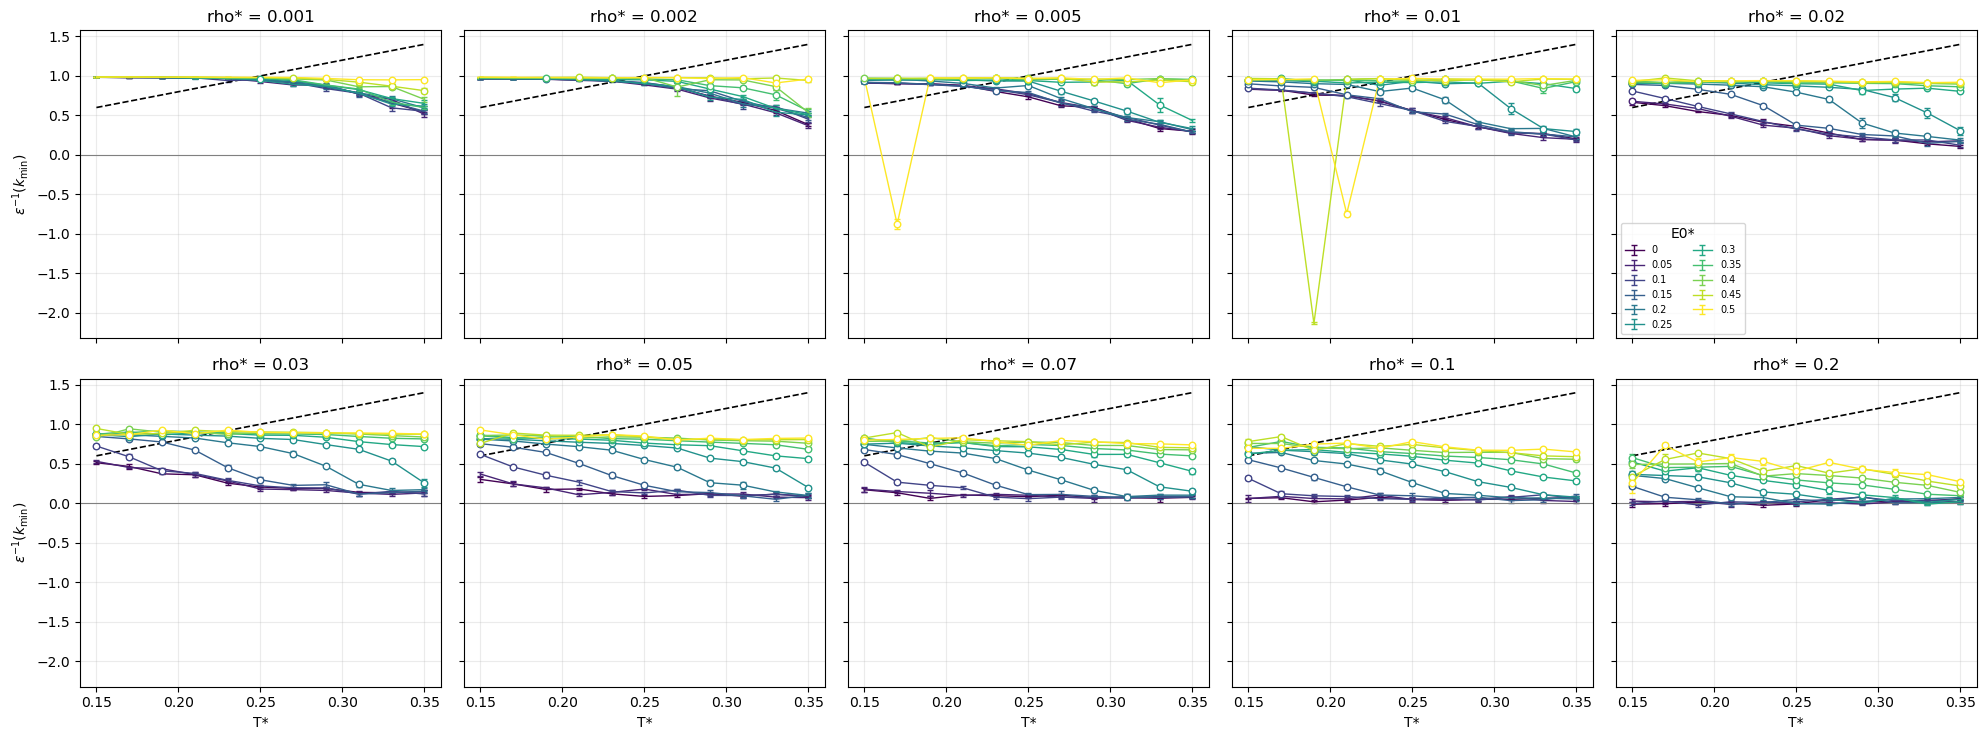

In [2]:
cmap = plt.get_cmap('viridis')
fig, axes = plt.subplots(2, 5, figsize=(20, 7.5), sharex=True, sharey=True)
tt = np.linspace(min(T), max(T), 50)
for ax, rho in zip(axes.flat, RHO):
    for i, e0 in enumerate(E0):
        d = kmin[(kmin.rho_star == rho) & (kmin.E0_star == e0)].sort_values('T_star')
        c = cmap(i / (len(E0) - 1))
        ax.errorbar(d.T_star, d.inv_eps, yerr=d.inv_eps_sem, color=c, lw=1, capsize=2, label=f'{e0:g}')
        cl = d[d.clustered]
        ax.scatter(cl.T_star, cl.inv_eps, facecolors='white', edgecolors=c, s=22, zorder=3)
    ax.plot(tt, 4 * tt, 'k--', lw=1.2)
    ax.axhline(0, color='gray', lw=0.8)
    ax.set_title(f'rho* = {rho:g}'); ax.grid(alpha=0.25)
for ax in axes[1]: ax.set_xlabel('T*')
for ax in axes[:, 0]: ax.set_ylabel(r'$\epsilon^{-1}(k_{\min})$')
axes[0, -1].legend(title='E0*', fontsize=7, ncol=2)
fig.tight_layout(); plt.show()

## 1b. 1/ε(k) vs kσ for every ρ*, at one fixed T* (panel (b) of the vortex_diagnostics PDF)
One panel per ρ*, one curve per E0*. Open markers: clustered state. Dashed: the BKT level $4T^*$. Dotted: Debye–Hückel for the plasma, $\epsilon^{-1}=k^2/(k^2+\kappa_D^2)$ with $(\kappa_D\sigma)^2 = 2\pi\rho^*/T^*$.
A conductor's curve falls toward 0 as k → 0; a dielectric's levels off at a finite value (≥ 4T* in the bound phase). Each density only reaches kσ from $2\pi\sqrt{\rho^*/N}$ to about 4× that.

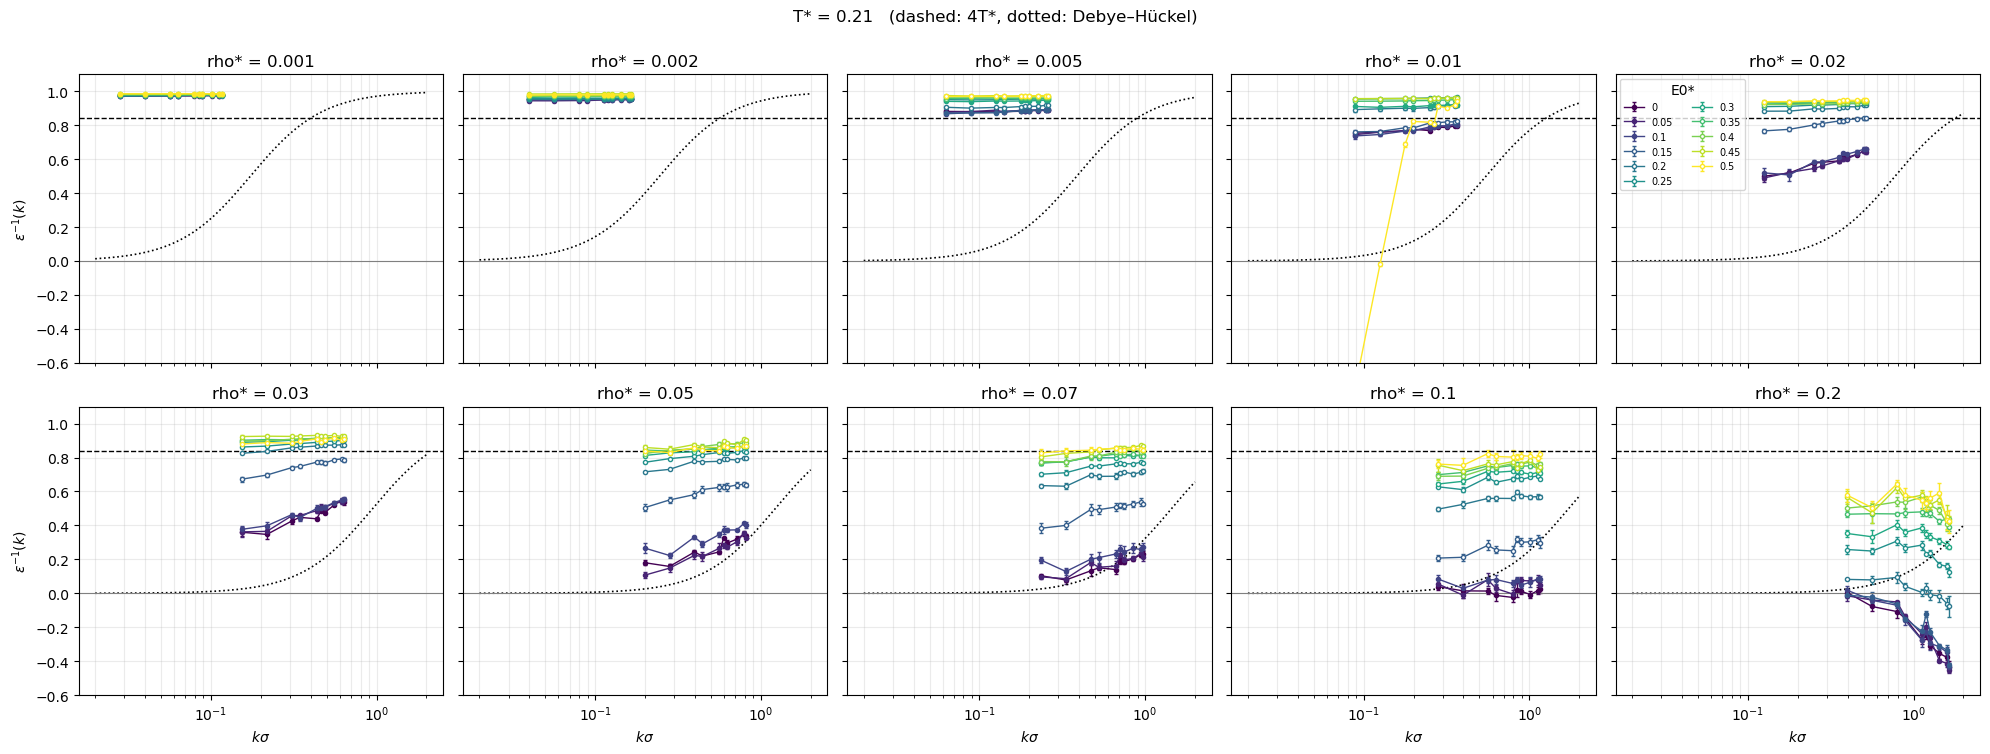

In [3]:
T_FIXED = 0.21          # choose any grid value: 0.15, 0.17, ..., 0.35 (4T* = 0.84 here)
cmap = plt.get_cmap('viridis')
fig, axes = plt.subplots(2, 5, figsize=(20, 7.5), sharex=True, sharey=True)
for ax, rho in zip(axes.flat, RHO):
    for i, e0 in enumerate(E0):
        d = table[np.isclose(table.rho_star, rho) & np.isclose(table.T_star, T_FIXED)
                  & np.isclose(table.E0_star, e0)].sort_values('m2')
        c = cmap(i / (len(E0) - 1))
        clustered = d.S_NN.iloc[0] > CLUSTER_FACTOR * N
        ax.errorbar(d.k_sigma, d.inv_eps, yerr=d.inv_eps_sem, color=c, lw=1, ms=3, capsize=1.5,
                    marker='o', mfc='white' if clustered else c, label=f'{e0:g}')
    kk = np.geomspace(0.02, 2, 200)
    kD2 = 2 * np.pi * rho / T_FIXED
    ax.plot(kk, kk**2 / (kk**2 + kD2), 'k:', lw=1.2)
    ax.axhline(4 * T_FIXED, color='k', ls='--', lw=1)
    ax.axhline(0, color='gray', lw=0.8)
    ax.set(xscale='log', title=f'rho* = {rho:g}', ylim=(-0.6, 1.1))
    ax.grid(alpha=0.25, which='both')
for ax in axes[1]: ax.set_xlabel(r'$k\sigma$')
for ax in axes[:, 0]: ax.set_ylabel(r'$\epsilon^{-1}(k)$')
axes[0, -1].legend(title='E0*', fontsize=7, ncol=2)
fig.suptitle(f'T* = {T_FIXED:g}   (dashed: 4T*, dotted: Debye–Hückel)', y=1.0)
fig.tight_layout(); plt.show()

## 1c. 1/ε(k) vs kσ for every ρ* on one plot, at fixed (T*, E0*)
Default E0* = 0 (pure Coulomb gas), where Debye–Hückel (dotted, same color as each density) is the reference for the plasma.
Low densities sit on the dielectric side (above 4T*), high densities on the conductor side. Negative values at ρ* = 0.2 are overscreening (charge alternation in a dense Coulomb fluid), the dip in panel (b) of the PDF. The y-axis stops at −0.6, so the few single-state spikes (down to −2.1) are cut off.

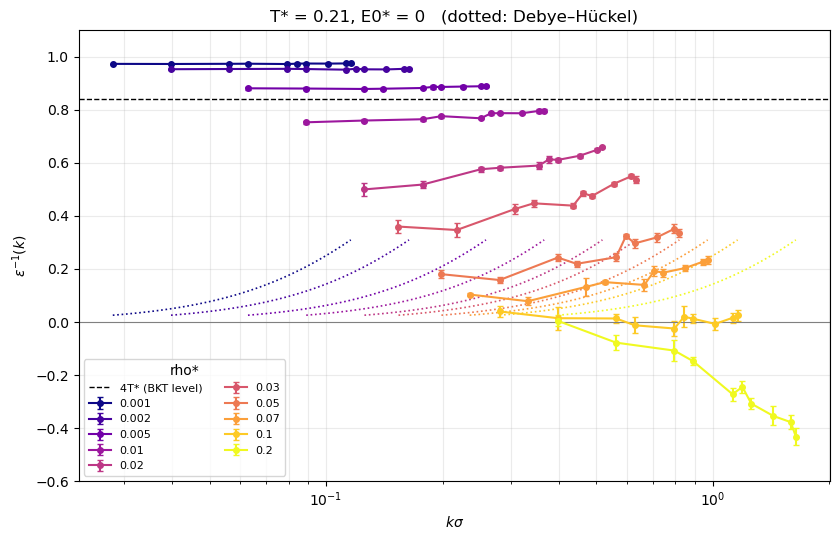

In [4]:
T_FIXED_C, E0_FIXED_C = 0.21, 0.0
cmap_r = plt.get_cmap('plasma')
fig, ax = plt.subplots(figsize=(8.5, 5.5))
for i, rho in enumerate(RHO):
    d = table[np.isclose(table.rho_star, rho) & np.isclose(table.T_star, T_FIXED_C)
              & np.isclose(table.E0_star, E0_FIXED_C)].sort_values('m2')
    c = cmap_r(i / (len(RHO) - 1))
    clustered = d.S_NN.iloc[0] > CLUSTER_FACTOR * N
    ax.errorbar(d.k_sigma, d.inv_eps, yerr=d.inv_eps_sem, color=c, marker='o', ms=4, capsize=2,
                mfc='white' if clustered else c, label=f'{rho:g}')
    kk = np.geomspace(d.k_sigma.min(), d.k_sigma.max(), 100)
    kD2 = 2 * np.pi * rho / T_FIXED_C
    ax.plot(kk, kk**2 / (kk**2 + kD2), ':', color=c, lw=1.2)
ax.axhline(4 * T_FIXED_C, color='k', ls='--', lw=1, label='4T* (BKT level)')
ax.axhline(0, color='gray', lw=0.8)
ax.set(xscale='log', xlabel=r'$k\sigma$', ylabel=r'$\epsilon^{-1}(k)$', ylim=(-0.6, 1.1),
       title=f'T* = {T_FIXED_C:g}, E0* = {E0_FIXED_C:g}   (dotted: Debye–Hückel)')
ax.grid(alpha=0.25, which='both'); ax.legend(title='rho*', fontsize=8, ncol=2)
fig.tight_layout(); plt.show()

## 2. BKT crossings: where 1/ε(k_min) = 4T*

For each (ρ*, E0*), linear interpolation between the two grid temperatures where $\epsilon^{-1}-4T^*$ changes sign from + to − (same method as 9.6).
The last + → − crossing is used (the curve stays conducting above it), so an isolated low-T spike cannot fake a crossing; `n_crossings > 1` marks a noisy curve and makes it unreliable. The error range comes from repeating the interpolation with $\epsilon^{-1}\pm$SEM.
`reliable` = exactly one crossing, and both bracketing states are uniform (not clustered) and not drifting.

In [5]:
def crossing(x, y):
    # Last + to - sign change of y(x), so the curve stays below 4T* afterwards;
    # single-state spikes at low T cannot create a spurious crossing. Returns interpolated x or NaN.
    for i in reversed(range(len(x) - 1)):
        if y[i] >= 0 > y[i + 1]:
            return x[i] + (x[i + 1] - x[i]) * y[i] / (y[i] - y[i + 1]), i
    return np.nan, None

rows = []
for (rho, e0), d in kmin.groupby(['rho_star', 'E0_star']):
    d = d.sort_values('T_star')
    x, y, s = d.T_star.to_numpy(), d.diff_4T.to_numpy(), d.inv_eps_sem.to_numpy()
    t_c, i = crossing(x, y)
    n_cross = int(np.sum((y[:-1] >= 0) & (y[1:] < 0)))
    t_hi, _ = crossing(x, y + s)    # 1/eps shifted up -> crossing moves to higher T
    t_lo, _ = crossing(x, y - s)
    if i is None:
        status = 'conductor_at_all_T' if (y < 0).all() else ('dielectric_at_all_T' if (y >= 0).all() else 'no_clean_crossing')
        reliable = False; clustered = drifting = np.nan
    else:
        pair = d.iloc[[i, i + 1]]
        clustered, drifting = bool(pair.clustered.any()), bool(pair.drifting.any())
        reliable = not (clustered or drifting) and n_cross == 1
        status = 'crossing'
    rows.append(dict(rho_star=rho, E0_star=e0, T_BKT=t_c, T_BKT_low=t_lo, T_BKT_high=t_hi,
                     n_crossings=n_cross, status=status, bracket_clustered=clustered,
                     bracket_drifting=drifting, reliable=reliable))
crossings = pd.DataFrame(rows)
crossings.to_csv(RESULTS / 'bkt_crossings.csv', index=False)
print(crossings.status.value_counts().to_string())
print('reliable crossings:', int(crossings.reliable.sum()))
display(crossings.pivot_table(index='E0_star', columns='rho_star', values='T_BKT').round(3))

status
crossing              89
conductor_at_all_T    21
reliable crossings: 15


rho_star,0.001,0.002,0.005,0.010,0.020,0.030,0.050,0.070,0.100,0.200
E0_star,,,,,,,,,,
0.00,0.240,0.233,0.215,0.190,0.161,NaN,NaN,NaN,NaN,NaN
0.05,0.238,0.232,0.216,0.194,0.164,NaN,NaN,NaN,NaN,NaN
0.10,0.236,0.234,0.215,0.194,0.174,0.161,0.152,NaN,NaN,NaN
0.15,0.240,0.233,0.214,0.201,0.200,0.192,0.174,0.161,NaN,NaN
0.20,0.240,0.232,0.219,0.216,0.219,0.207,0.188,0.173,0.159,NaN
0.25,0.240,0.234,0.234,0.225,0.224,0.215,0.196,0.184,0.169,NaN
0.30,0.242,0.238,0.236,0.230,0.228,0.221,0.204,0.187,0.164,NaN
0.35,0.244,0.242,0.240,0.234,0.232,0.224,0.211,0.191,0.183,NaN
0.40,0.244,0.245,0.243,0.239,0.233,0.221,0.207,0.200,0.181,NaN


## 3. Check against what we already know (9.6, E0* = 0, N = 50)

In [6]:
ref = ref96[ref96.N == N][['rho_star', 'T_cross']].rename(columns={'T_cross': 'T_BKT_9.6'})
new = crossings[crossings.E0_star == 0][['rho_star', 'T_BKT', 'T_BKT_low', 'T_BKT_high', 'reliable']]
comparison = ref.merge(new, on='rho_star', how='left')
comparison['difference'] = comparison['T_BKT'] - comparison['T_BKT_9.6']
display(comparison.round(4))

,rho_star,T_BKT_9.6,T_BKT,T_BKT_low,T_BKT_high,reliable,difference
0,0.001,0.2387,0.2400,0.2395,0.2406,False,0.0013
1,0.005,0.2145,0.2152,0.2141,0.2166,True,0.0007
2,0.010,0.1939,0.1897,0.1874,0.1932,True,-0.0042


## 4. Conductor vs dielectric map: $\beta g\,\epsilon^{-1} = \epsilon^{-1}/T^*$
≥ 4: dielectric (molecular gas). → 0: conductor (plasma/liquid, $S_{QQ}(k_{\min})\to2\pi T^*$). White contour: BKT line (= 4). Hatched: clustered.

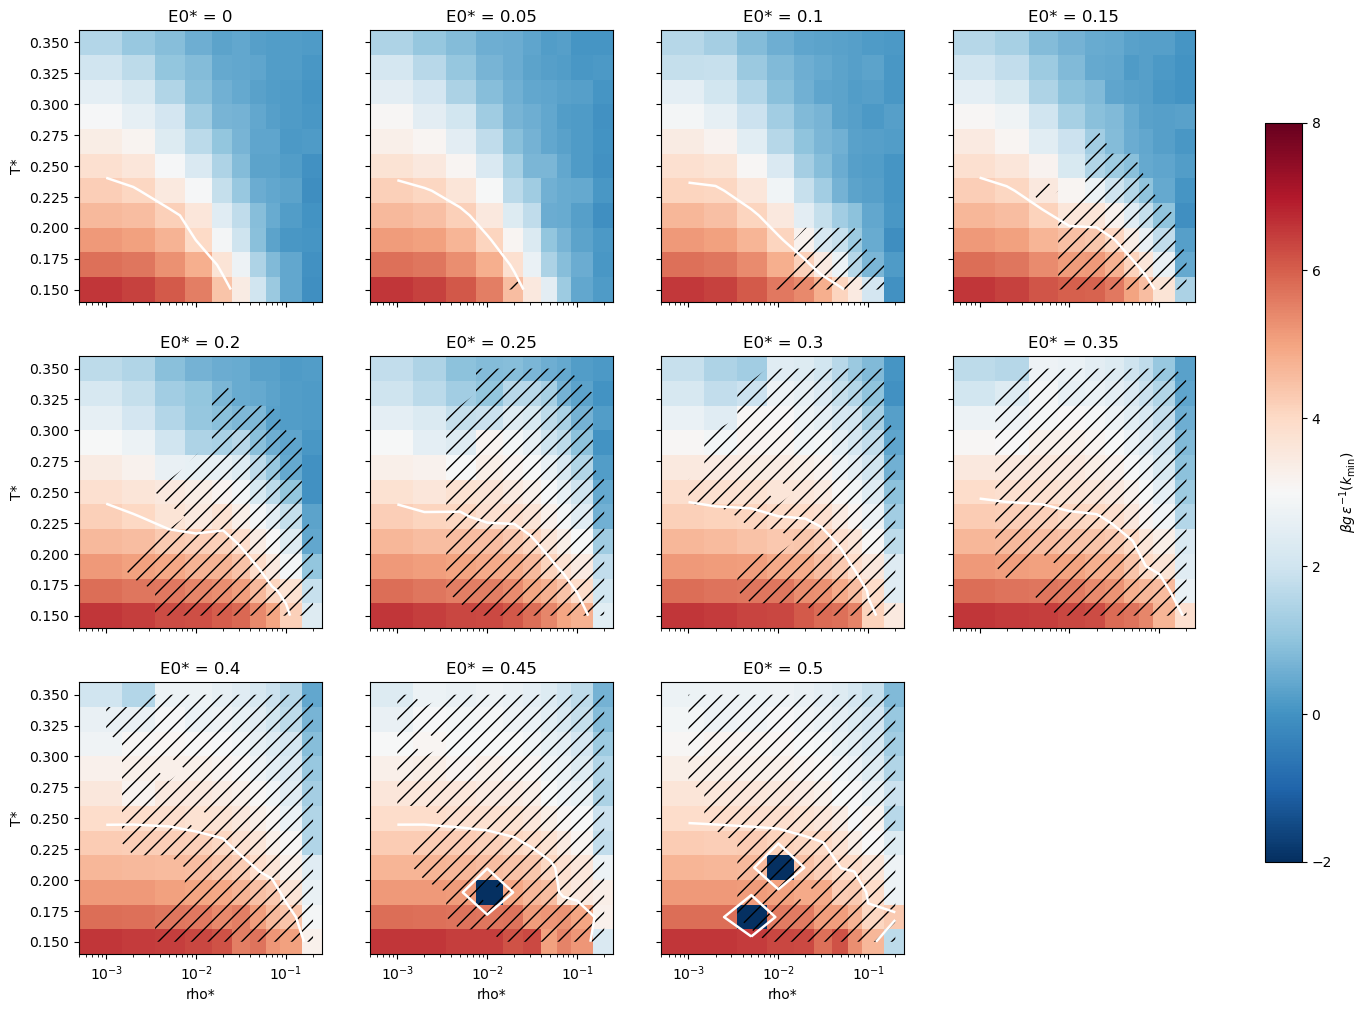

In [7]:
def grid(df, value):
    return df.pivot_table(index='T_star', columns='rho_star', values=value).reindex(index=T, columns=RHO).to_numpy()

fig, axes = plt.subplots(3, 4, figsize=(18, 12), sharex=True, sharey=True)
for ax, e0 in zip(axes.flat, E0):
    d = kmin[kmin.E0_star == e0]
    Z = grid(d, 'beta_g_inv_eps')
    im = ax.pcolormesh(RHO, T, Z, cmap='RdBu_r', vmin=-2, vmax=8, shading='nearest')
    ax.contour(RHO, T, Z, levels=[4], colors='white', linewidths=1.8)
    ax.contourf(RHO, T, grid(d, 'clustered').astype(float), levels=[0.5, 1.5], colors='none', hatches=['//'])
    ax.set(xscale='log', title=f'E0* = {e0:g}')
axes.flat[-1].axis('off')
for ax in axes[-1]: ax.set_xlabel('rho*')
for ax in axes[:, 0]: ax.set_ylabel('T*')
fig.colorbar(im, ax=axes, label=r'$\beta g\,\epsilon^{-1}(k_{\min})$', shrink=0.8)
plt.show()

## 5. Combined phase diagram, one panel per E0*

* Background: $S_{NN}(k_{\min})/N$ (log color) — dark = uniform, bright = clustered.
* Orange contour: clustering boundary $S_{NN}(k_{\min}) = $ CLUSTER_FACTOR·N (liquid–gas signal).
* Cyan line: BKT line $T_{BKT}(\rho^*)$ from 1/ε. Filled = reliable, open = bracketing states clustered or drifting. Error bars from ±SEM.
* Stars: 9.6 reference (E0* = 0).
* Where the two lines meet is a rough tricritical-point estimate (N = 50 only).

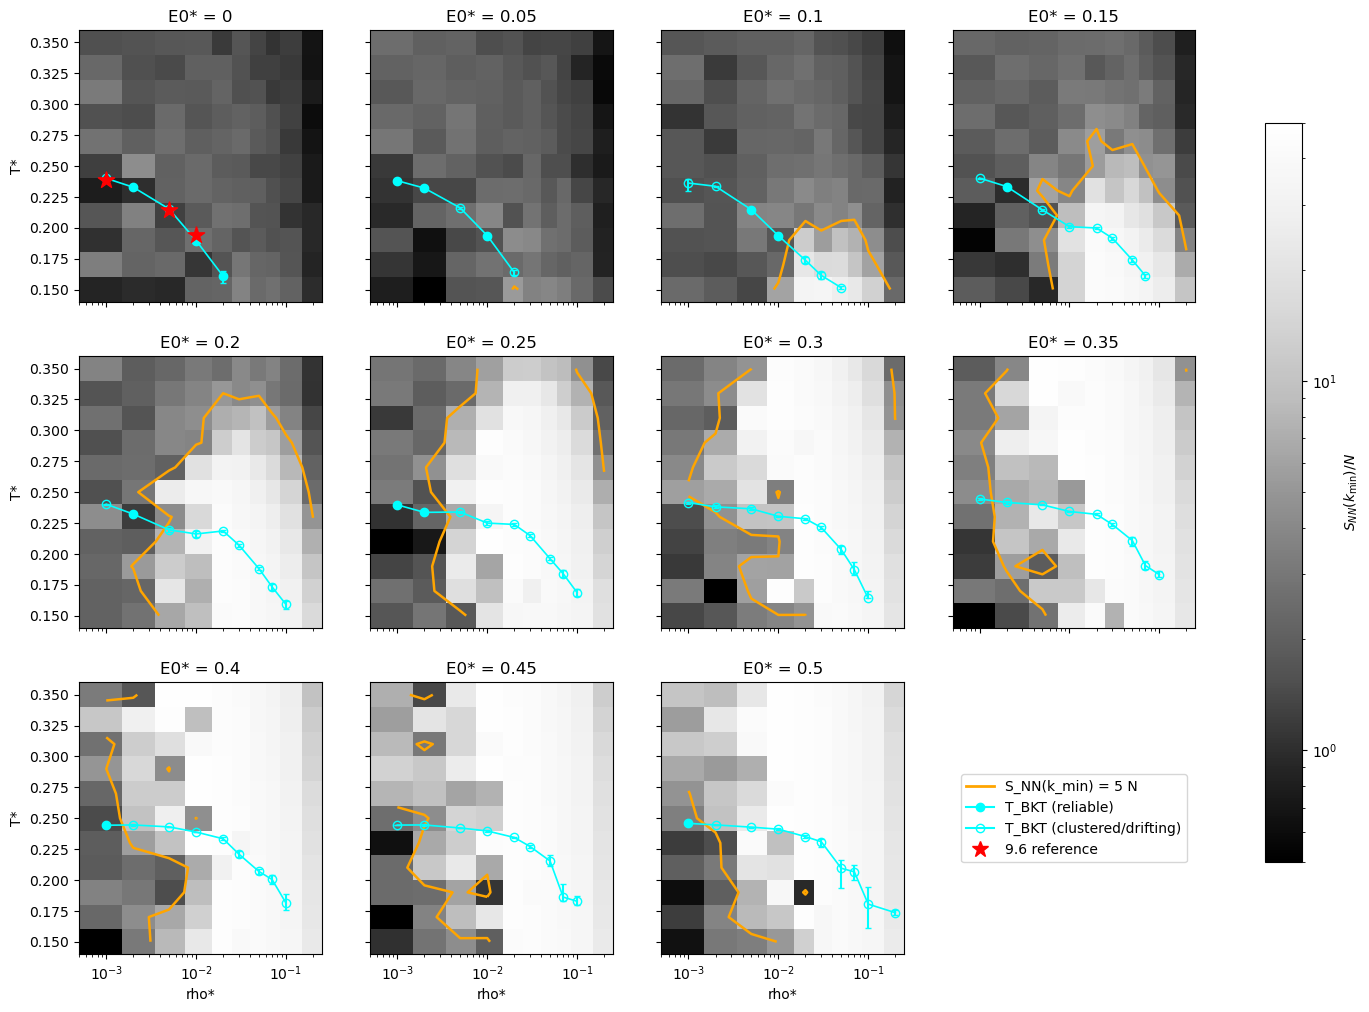

In [8]:
from matplotlib.colors import LogNorm
fig, axes = plt.subplots(3, 4, figsize=(18, 12), sharex=True, sharey=True)
for ax, e0 in zip(axes.flat, E0):
    d = kmin[kmin.E0_star == e0]
    Z = grid(d, 'S_NN') / N
    im = ax.pcolormesh(RHO, T, Z, norm=LogNorm(vmin=0.5, vmax=N), cmap='Greys_r', shading='nearest')
    ax.contour(RHO, T, Z, levels=[CLUSTER_FACTOR], colors='orange', linewidths=1.8)
    c = crossings[(crossings.E0_star == e0) & crossings.T_BKT.notna()].sort_values('rho_star')
    ax.plot(c.rho_star, c.T_BKT, color='cyan', lw=1.2)
    for _, r in c.iterrows():
        yerr = [[max(r.T_BKT - r.T_BKT_low, 0) if np.isfinite(r.T_BKT_low) else 0],
                [max(r.T_BKT_high - r.T_BKT, 0) if np.isfinite(r.T_BKT_high) else 0]]
        ax.errorbar(r.rho_star, r.T_BKT, yerr=yerr, fmt='o', ms=6, capsize=2, color='cyan',
                    mfc='cyan' if r.reliable else 'none')
    if e0 == 0:
        ref = ref96[ref96.N == N]
        ax.scatter(ref.rho_star, ref.T_cross, marker='*', s=150, color='red', zorder=4)
    ax.set(xscale='log', title=f'E0* = {e0:g}', ylim=(min(T) - 0.01, max(T) + 0.01))
axes.flat[-1].axis('off')
for ax in axes[-1]: ax.set_xlabel('rho*')
for ax in axes[:, 0]: ax.set_ylabel('T*')
handles = [Line2D([], [], color='orange', lw=2, label=f'S_NN(k_min) = {CLUSTER_FACTOR:g} N'),
           Line2D([], [], color='cyan', marker='o', label='T_BKT (reliable)'),
           Line2D([], [], color='cyan', marker='o', mfc='none', label='T_BKT (clustered/drifting)'),
           Line2D([], [], color='red', marker='*', ls='', ms=12, label='9.6 reference')]
axes.flat[-1].legend(handles=handles, loc='center')
fig.colorbar(im, ax=axes, label=r'$S_{NN}(k_{\min})/N$', shrink=0.8)
plt.show()

## 6. T_BKT(ρ*) for all E0* on one plot
Filled = reliable, open = flagged.

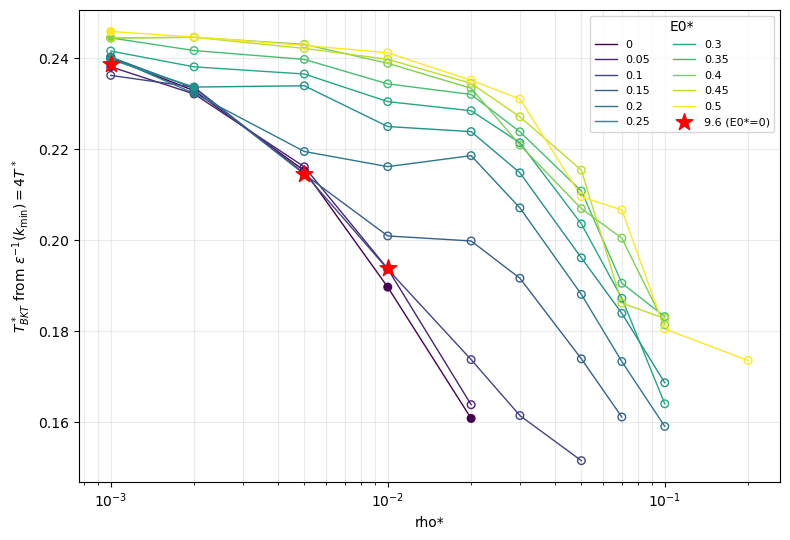

Not shown: (rho*, E0*) with no crossing in 0.15 <= T* <= 0.35:


rho_star,0.03,0.05,0.07,0.10,0.20
E0_star,,,,,
0.00,conductor_at_all_T,conductor_at_all_T,conductor_at_all_T,conductor_at_all_T,conductor_at_all_T
0.05,conductor_at_all_T,conductor_at_all_T,conductor_at_all_T,conductor_at_all_T,conductor_at_all_T
0.10,NaN,NaN,conductor_at_all_T,conductor_at_all_T,conductor_at_all_T
0.15,NaN,NaN,NaN,conductor_at_all_T,conductor_at_all_T
0.20,NaN,NaN,NaN,NaN,conductor_at_all_T
0.25,NaN,NaN,NaN,NaN,conductor_at_all_T
0.30,NaN,NaN,NaN,NaN,conductor_at_all_T
0.35,NaN,NaN,NaN,NaN,conductor_at_all_T
0.40,NaN,NaN,NaN,NaN,conductor_at_all_T


In [9]:
cmap = plt.get_cmap('viridis')
fig, ax = plt.subplots(figsize=(8, 5.5))
for i, e0 in enumerate(E0):
    c = crossings[(crossings.E0_star == e0) & crossings.T_BKT.notna()].sort_values('rho_star')
    col = cmap(i / (len(E0) - 1))
    ax.plot(c.rho_star, c.T_BKT, color=col, lw=1, label=f'{e0:g}')
    ax.scatter(c.rho_star, c.T_BKT, color=col, s=30,
               facecolors=[col if r else 'none' for r in c.reliable], zorder=3)
ref = ref96[ref96.N == N]
ax.scatter(ref.rho_star, ref.T_cross, marker='*', s=160, color='red', zorder=4, label='9.6 (E0*=0)')
ax.set(xscale='log', xlabel='rho*', ylabel=r'$T^*_{BKT}$ from $\epsilon^{-1}(k_{\min}) = 4T^*$')
ax.grid(alpha=0.25, which='both'); ax.legend(title='E0*', fontsize=8, ncol=2); fig.tight_layout(); plt.show()
print('Not shown: (rho*, E0*) with no crossing in 0.15 <= T* <= 0.35:')
display(crossings[crossings.T_BKT.isna()].pivot_table(index='E0_star', columns='rho_star', values='status', aggfunc='first'))